# 10 · Catalysis and heterogeneous kinetics

Most of the chemical industry runs on solid catalysts: a reactant adsorbs on a surface, reacts there, and the
product desorbs. Each step can limit the rate, and the resulting rate laws - Langmuir-Hinshelwood-Hougen-
Watson - have a form that power laws cannot mimic: they saturate, they pass through maxima, they are inhibited
by products. This notebook builds adsorption isotherms, derives LHHW rate laws, discriminates between
mechanisms with data, and follows a catalyst as it deactivates.

**What you will learn**
- use Langmuir isotherms including dissociative and competitive adsorption
- derive and recognise LHHW rate laws
- discriminate mechanisms with rate data
- model catalyst deactivation and the temperature-time trajectory

**Before you start:** notebooks 03 and 05  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import catalysis, datasets
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Adsorption: the Langmuir isotherm

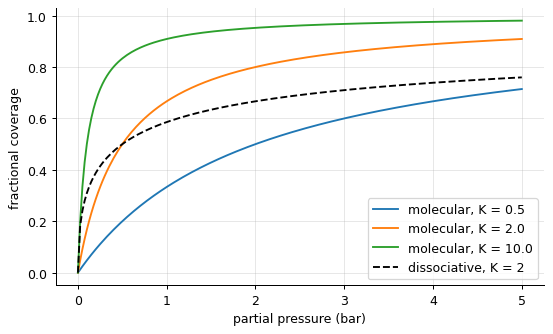

competitive adsorption of A and B at 1 bar each (K_B = 4 K_A): {'A': 0.182, 'B': 0.727} - B crowds A off the surface


In [2]:
p = np.linspace(0, 5, 200)
fig, ax = plt.subplots()
for K in (0.5, 2.0, 10.0):
    ax.plot(p, catalysis.langmuir_coverage(K, p), label=f"molecular, K = {K}")
ax.plot(p, catalysis.langmuir_dissociative(2.0, p), "k--", label="dissociative, K = 2")
ax.set(xlabel="partial pressure (bar)", ylabel="fractional coverage"); ax.legend(); plt.show()
comp = catalysis.langmuir_competitive({"A": 2.0, "B": 8.0}, {"A": 1.0, "B": 1.0})
print("competitive adsorption of A and B at 1 bar each (K_B = 4 K_A):", {k: round(v, 3) for k, v in comp.items()}, "- B crowds A off the surface")

Langmuir's isotherm - rate of adsorption proportional to the empty sites, of desorption to the covered ones
- gives a coverage that saturates: beyond a point, more pressure adds nothing because there are no sites
left. Competitive adsorption is the origin of inhibition: a strongly adsorbing product or poison occupies
the sites the reactant needs.

## LHHW rate laws

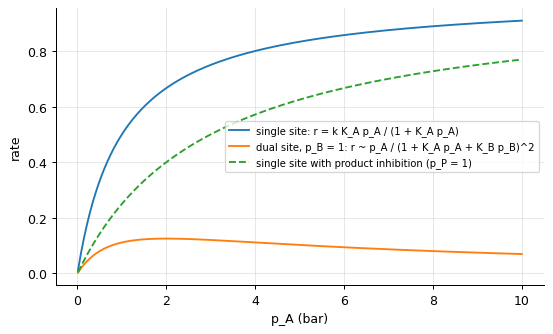

In [3]:
pA = np.linspace(0.01, 10, 300)
fig, ax = plt.subplots()
ax.plot(pA, catalysis.lhhw_rate(1.0, pA, K_A=1.0, mode="single"), label="single site: r = k K_A p_A / (1 + K_A p_A)")
ax.plot(pA, catalysis.lhhw_rate(1.0, pA, 1.0, K_A=1.0, K_B=1.0, mode="surface"), label="dual site, p_B = 1: r ~ p_A / (1 + K_A p_A + K_B p_B)^2")
ax.plot(pA, catalysis.lhhw_rate(1.0, pA, K_A=1.0, K_P=2.0, p_P=1.0, mode="single"), "--", label="single site with product inhibition (p_P = 1)")
ax.set(xlabel="p_A (bar)", ylabel="rate"); ax.legend(fontsize=8); plt.show()

A single-site mechanism gives a rate that saturates (first order at low pressure, zero order at high); a
dual-site surface reaction passes through a maximum, because the reactant crowds its partner off the
surface; product inhibition lowers everything. A power law fitted over a narrow range can mimic any of
these locally, which is why the *shape* over a wide range is what identifies a mechanism.

## Discriminating mechanisms with data

single-site fit: k K_A = 1.465, K_A = 1.477 (true 1.5, 1.5), rss = 1.29e-03
a power law fitted to the same data: order 0.36 - neither 0 nor 1, a sign that the mechanism saturates


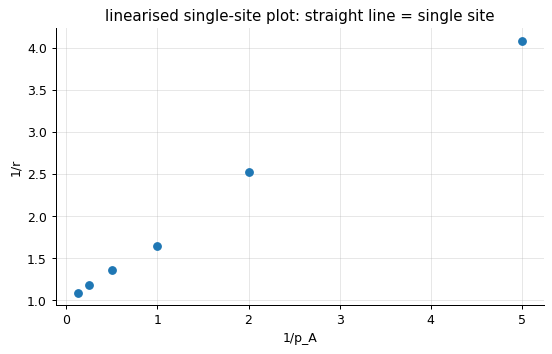

In [4]:
p_obs = np.array([0.2, 0.5, 1.0, 2.0, 4.0, 8.0])
r_obs = catalysis.lhhw_rate(1.0, p_obs, K_A=1.5, mode="single") * (1 + np.random.default_rng(3).normal(0, 0.03, 6))
fit = catalysis.fit_lhhw_single(p_obs, r_obs)
print(f"single-site fit: k K_A = {fit['k_K']:.3f}, K_A = {fit['K']:.3f} (true 1.5, 1.5), rss = {fit['rss']:.2e}")
n_fit = np.polyfit(np.log(p_obs), np.log(r_obs), 1)
print(f"a power law fitted to the same data: order {n_fit[0]:.2f} - neither 0 nor 1, a sign that the mechanism saturates")
plt.plot(1 / p_obs, 1 / r_obs, "o"); plt.xlabel("1/p_A"); plt.ylabel("1/r"); plt.title("linearised single-site plot: straight line = single site"); plt.show()

The reciprocal plot linearises the single-site law, as Lineweaver-Burk does for enzymes (notebook 16); a
straight line supports the mechanism and its slope and intercept give the constants, refined by nonlinear
regression. Testing several mechanisms against data over a wide range of pressures is the heart of
heterogeneous kinetics - and the reason a "fractional order of 0.4" should make you suspect a saturating
mechanism.

## Catalyst deactivation

first   order decay: k_d = 0.0075 1/h, rss = 0.0383
second  order decay: k_d = 0.0121 1/h, rss = 0.0064
linear  order decay: k_d = 0.0057 1/h, rss = 0.2216


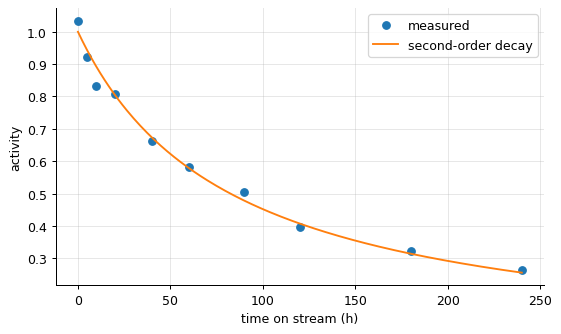

In [5]:
d = pd.read_csv(datasets.path("catalyst_deactivation.csv"), comment="#")
fits = {law: catalysis.fit_deactivation(d.t_h, d.activity, law) for law in ("first", "second", "linear")}
for law, f in fits.items():
    print(f"{law:<7} order decay: k_d = {f['k_d']:.4f} 1/h, rss = {f['rss']:.4f}")
best = min(fits, key=lambda l: fits[l]["rss"])
tt = np.linspace(0, 240, 200)
plt.plot(d.t_h, d.activity, "o", label="measured"); plt.plot(tt, catalysis.activity(tt, fits[best]["k_d"], best), label=f"{best}-order decay"); plt.xlabel("time on stream (h)"); plt.ylabel("activity"); plt.legend(); plt.show()

Catalysts die - by coking, sintering or poisoning - and the activity's time dependence tells which: coking
often follows second-order-like decay, sintering first order, poisoning by a feed impurity roughly linear.
The data pick second order clearly. Knowing the law lets the engineer schedule regeneration and, in the
meantime, compensate.

## Compensating by raising the temperature

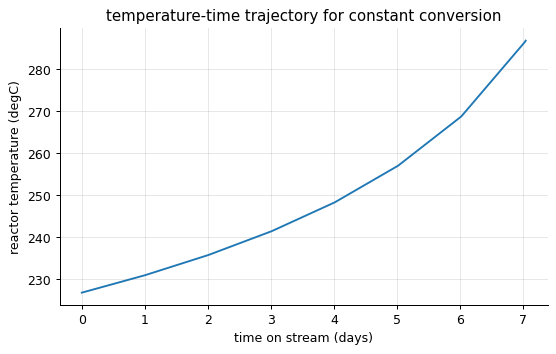

the temperature must rise 60 K over 7 days to hold conversion; it reaches the 560 K limit: True - time to regenerate


In [6]:
traj = catalysis.temperature_time_trajectory(k_d0=2.0, E_d=60e3, k0=1e8, Ea=50e3, T0=500.0, t_max=400 * 86400, T_max=560.0)
plt.plot(traj["t"] / 86400, traj["T"] - 273.15); plt.xlabel("time on stream (days)"); plt.ylabel("reactor temperature (degC)"); plt.title("temperature-time trajectory for constant conversion"); plt.show()
print(f"the temperature must rise {traj['T'][-1]-500:.0f} K over {traj['t'][-1]/86400:.0f} days to hold conversion; it reaches the 560 K limit: {traj['reached_T_max']} - time to regenerate")

Raising the temperature offsets the loss of activity - until the maximum allowable temperature is reached,
and the accelerating deactivation (its own activation energy is higher than the reaction's) makes the
climb steepen. Refinery reformers and hydrotreaters run exactly this trajectory over a cycle of months
between regenerations.

## Inside the algorithm: the single-site rate law from site balances

In [7]:
K_A_, p_ = 1.5, 2.0
theta_A = K_A_ * p_ / (1 + K_A_ * p_)            # coverage from the site balance
print("by hand: r = k theta_A =", 1.0 * theta_A, "; library:", float(catalysis.lhhw_rate(1.0, p_, K_A=K_A_, mode="single")))

by hand: r = k theta_A = 0.75 ; library: 0.75


## Exercises
1. Derive the rate law for A + B -> C when A adsorbs molecularly, B dissociatively, and the surface reaction is rate limiting. Plot it against p_A at fixed p_B and find the pressure of maximum rate.
2. The deactivation data are refitted with the nth-order law with n free. Fit n and k_d by nonlinear least squares and report whether n = 2 is within the uncertainty. How long until the activity falls to 0.3?
3. **Implement it yourself:** integrate da/dt = -k_d a^2 with solve_ivp and confirm it reproduces `catalysis.activity` with the 'second' law.